In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import sklearn.linear_model
import numpy as np

# Regression

Example of linear regression using sklearn, using a private datast involving athletes and non-athletes. 

In [ ]:
# Read the dataset
import pandas
df = pandas.read_csv('data/athletes.csv')
df.head(), len(df)

(   Female  Age_y  Weight_kg  Height_cm  LV_mass_g  Athlete
 0     1.0   31.0       54.0      163.0       65.3      1.0
 1     1.0   39.0       54.0      162.0       91.5      1.0
 2     1.0   33.0       65.0      176.0        NaN      1.0
 3     1.0   41.0       55.0      160.0       76.9      1.0
 4     0.0   27.0       67.0      174.0        NaN      1.0,
 261)

The model score is: 0.4049917266702423


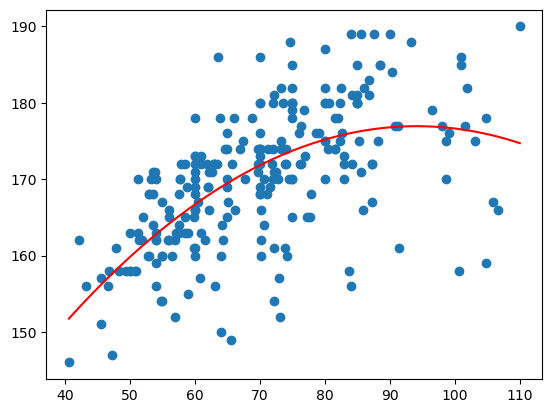

In [14]:
# Train a regressor to predict weight from height, using polynomial features

# Remove the nans ... next sesion we will see why
df_filtered = df[['Weight_kg', 'Height_cm']].dropna()

lm = sklearn.pipeline.Pipeline([
    ('poly', sklearn.preprocessing.PolynomialFeatures(degree=2)), # Equivalent to manually adding the columns
    ('linear', sklearn.linear_model.LinearRegression())
])
X = df_filtered[['Weight_kg']].values
y = df_filtered['Height_cm'].values
lm.fit(X,y)
X_sample = np.linspace(np.min(X), np.max(X), 100).reshape(-1,1)
plt.plot(X_sample, lm.predict(X_sample), label='prediction', color = 'r')
plt.scatter(X, y, label = 'train', marker ='o')
print('The model score is:' , lm.score(X, y))



# The same as before, but adding manually the measurements


The model score is: 0.40572175854527304


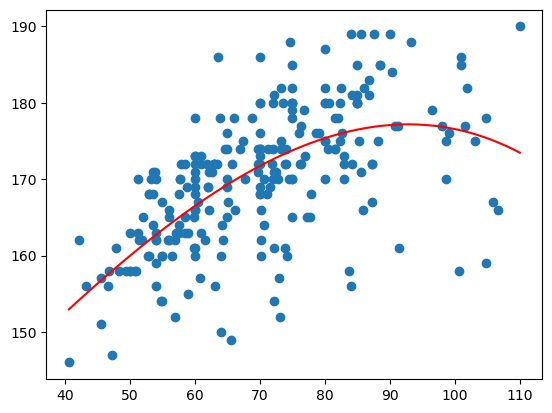

In [28]:
# Remove the nans ... next sesion we will see why
df_filtered = df[['Weight_kg', 'Height_cm']].dropna()
df_filtered['Weight_kg_squared'] = df_filtered['Weight_kg']**2
df_filtered['Weight_kg_cubed'] = df_filtered['Weight_kg']**3

lm =  sklearn.linear_model.LinearRegression()

X = df_filtered[['Weight_kg', 'Weight_kg_squared', 'Weight_kg_cubed']].values
y = df_filtered['Height_cm'].values
lm.fit(X,y)
X_sample = np.linspace(np.min(X[:,0]), np.max(X[:,0]), 100).reshape(-1,1)
X_sample = np.hstack([X_sample, X_sample**2, X_sample**3])
plt.plot(X_sample[:, 0], lm.predict(X_sample), label='prediction', color = 'r')
plt.scatter(X[:, 0], y, label = 'train', marker ='o')
print('The model score is:' , lm.score(X, y))



# Train / test split
Now, let's see what happens when we split the data into a training and a test set. We will use 80% of the data for testing and 20% for training.

The train model score is: 0.6671756315070374
The test model score is: 0.29915203956269043


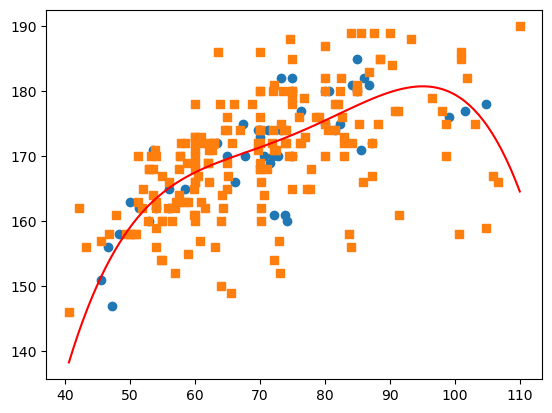

In [19]:
X = df_filtered[['Weight_kg']].values
y = df_filtered['Height_cm'].values

X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X,y, test_size=0.8, random_state=42)

lm = sklearn.pipeline.Pipeline([
    ('poly', sklearn.preprocessing.PolynomialFeatures(degree=4)),
    ('linear', sklearn.linear_model.LinearRegression())
])


lm.fit(X_train, y_train)
X_sample = np.linspace(np.min(X), np.max(X), 100).reshape(-1,1)
plt.plot(X_sample, lm.predict(X_sample), label='prediction', color = 'r')
plt.scatter(X_train, y_train, label = 'train', marker ='o')
plt.scatter(X_test, y_test, label = 'test', marker ='s')
print('The train model score is:' , lm.score(X_train, y_train))
print('The test model score is:' , lm.score(X_test, y_test))


Text(0, 0.5, 'R^2 score')

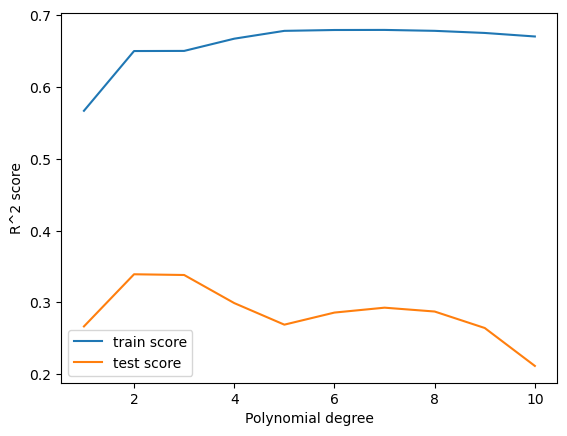

In [21]:
train_score = []
test_score = []
for degree in [1,2,3,4,5,6,7,8,9,10]:
    lm = sklearn.pipeline.Pipeline([
        ('poly', sklearn.preprocessing.PolynomialFeatures(degree=degree)),
        ('linear', sklearn.linear_model.LinearRegression())
    ])
    lm.fit(X_train, y_train)
    train_score.append(lm.score(X_train, y_train))
    test_score.append(lm.score(X_test, y_test))
plt.plot(range(1,11), train_score, label='train score')
plt.plot(range(1,11), test_score, label='test score')
plt.legend()
plt.xlabel('Polynomial degree')
plt.ylabel('R^2 score')

# Regularisation

Do the previous one, but changing the linear model by sklearn.linear_model.Ridge and sklearn.linear_model.Lasso. Use the default parameters. You will need to add a Standard Scaler. Why?

Check that the model coefficients tend to 0 in the case of Lasso. Y